# PHM 2015 | Scouting the Data and Designing Case Points

This notebook uses the 46 training sites to decide how a three-hour measurement window should become a case. It investigates class support, episode duration, coverage, operating state, unusual channel values, dependence between cases, and feature redundancy. A small logistic-regression pilot tests whether the proposed summaries carry useful information across sites.

The saved validation and test sites remain reserved for later decisions and evaluation. Every analysis view below filters the existing manifest to training. The [preprocessing notebook](preprocessing_experimental_data.ipynb) explains the underlying clock and interval rules. The [version history](version_history/v0.2.0_eda_case_design.md) records the changes and explains the functions.

**A case's metrics have two sources.** Summary statistics describe its measurements. A fitted logistic model supplies its three class scores. Coefficients and intercepts belong to that model, and a case refers to them by model ID. Later sections show the arithmetic linking these quantities.

## 1. Open the Prepared Data

Use the existing project Python kernel and run the notebook from top to bottom. One DuckDB worker and a 256 MB database buffer budget keep the large signal table on disk. Window extraction runs in site batches, and fitting runs with one numerical worker. The saved database contains the scouting sample and the diagnostic results.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
import hashlib
import json
import platform
import sys

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from scipy.special import softmax
from sklearn.metrics import classification_report, confusion_matrix
get_ipython().run_line_magic("matplotlib", "inline")

project = Path.cwd().resolve()
if (project / "Files" / "phm_case_design.py").is_file():
    project = project / "Files"
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
import phm_case_design as design

source = project.parent / "Datasets" / "PHM15-prepared" / "case_inputs.duckdb"
assert source.is_file(), "Run the preprocessing notebook first."
destination = source.parent / "case_design.duckdb"
figures = source.parent / "case_design_figures"
figures.mkdir(exist_ok=True)
scratch = TemporaryDirectory(prefix="case-design-", dir=source.parent)
staged = Path(scratch.name) / destination.name
db = duckdb.connect(str(staged), config={"threads": 1, "memory_limit": "256MB"})
design.attach_training_views(db, source)
started = perf_counter()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})
colours = ["#52677f", "#c36b30", "#347d70"]
labels = list(design.LABELS)
short_labels = ["No recorded target", "Runtime excessive", "Supply too cold"]

def show_figure(figure, filename):
    figure.savefig(figures / filename, dpi=170, bbox_inches="tight")
    display(figure)
    plt.close(figure)

print(f"Kernel {sys.executable}")
print(f"Python {platform.python_version()} | DuckDB {duckdb.__version__} | scikit-learn {sklearn.__version__}")

Kernel C:\Users\ges2j\OneDrive\Desktop\Assessments\CP5403\Files\.venv\Scripts\python.exe
Python 3.14.8 | DuckDB 2.0.0 | scikit-learn 1.9.1


## 2. Identify What the Clock Overrepresents

Count eligible clock ticks, sites, and distinct positive episodes separately. Long episodes supply many ticks, which can dominate a model trained on every quarter hour. Duration quantiles describe the merged episodes before case sampling.

In [2]:
support = db.execute('''select reference_label, count(*) as ticks,
    count(distinct site_id) as sites, count(distinct episode_id) as episodes
    from train_decisions where status='eligible' group by 1''').df().set_index("reference_label").reindex(labels)
support["tick_share"] = support.ticks / support.ticks.sum()
duration = db.execute('''select event_name, count(*) as episodes,
    quantile_cont(epoch(end_at-start_at)/60, 0.1) as p10_minutes,
    median(epoch(end_at-start_at)/60) as median_minutes,
    quantile_cont(epoch(end_at-start_at)/60, 0.9) as p90_minutes
    from train_episodes group by 1 order by 1''').df()
status = db.execute("select status,count(*) as ticks from train_decisions group by 1 order by ticks desc").df()
site_support = db.execute('''select site_id,reference_label,count(*) as ticks,
    count(distinct episode_id) as episodes from train_decisions
    where status='eligible' group by 1,2 order by 1,2''').df()
for name, frame in [("training_support", support.reset_index()), ("episode_durations", duration),
                    ("training_exclusions", status), ("site_support", site_support)]:
    design.save_frame(db, name, frame)
display(support.round(4))
display(duration.round(1))
display(status)
display(Markdown(f"Controls supply **{support.loc[design.CONTROL, 'tick_share']:.1%}** of eligible training ticks. "
    f"The two targets have eligible episodes at **{int(support.loc[design.TARGETS[0], 'sites'])}** and "
    f"**{int(support.loc[design.TARGETS[1], 'sites'])}** sites. The case sample therefore caps each site's "
    "contribution and samples each positive episode once."))

,ticks,sites,episodes,tick_share
reference_label,,,,
NoRecordedTarget,2296481,46,0,0.9456
RuntimeExcessive,86113,45,4607,0.0355
SupplyTempTooCold,46024,36,8067,0.0190


,event_name,episodes,p10_minutes,median_minutes,p90_minutes
0,RuntimeExcessive,4678,45.0,210.0,420.2
1,SupplyTempTooCold,8972,14.9,30.2,224.8


,status,ticks
0,eligible,2428618
1,control_unbracketed,481606
2,control_log_outage,63288
3,both_targets_active,5570
4,insufficient_ch1,2690
5,partial_history,156
6,unresolved_target,65


Controls supply **94.6%** of eligible training ticks. The two targets have eligible episodes at **45** and **36** sites. The case sample therefore caps each site's contribution and samples each positive episode once.

## 3. Check the Channel Scale and State Encoding

The seven channel IDs retain their source positions and native scales. Approximate channel quantiles and site medians use DuckDB's streaming aggregate over all retained training readings. Extrema and distinct-value counts are exact. The state table checks which strings occur and how widely they occur.

Low cardinality can indicate an encoded state or control level. Channels 3, 6, and 7 have especially few distinct values. Their numerical spacing needs verification, so the main pilot uses channels 1, 2, 4, and 5 and compares an expanded variant containing all seven. The stored case summaries cover every channel.

In [3]:
channel_profile = design.channel_audit(db)
states = db.execute('''select operating_state,count(*) as bins,count(distinct site_id) as sites
    from train_bins group by 1 order by bins desc''').df()
site_levels = db.execute('''select site_id,approx_quantile(ch1,0.5) as ch1_median,approx_quantile(ch2,0.5) as ch2_median,
    count(distinct component) as historical_components from train_bins group by 1 order by 1''').df()
design.save_frame(db, "channel_profile", channel_profile)
design.save_frame(db, "operating_states", states)
design.save_frame(db, "site_levels", site_levels)
display(channel_profile.round(2))
display(states)
display(site_levels.describe().round(2))
display(Markdown("The ranges contain values far outside the central quantiles. Their physical meaning is "
    "unverified. Keep the raw summaries and compare a fitting-fold clipping sensitivity before choosing "
    "any outlier treatment. Zero nulls among retained readings can coexist with entirely absent bins or components."))

,channel,nulls,unique_values,minimum,p01,p25,p50,p75,p99,maximum
0,ch1,0,635,-777.0,643.02,712.00,727.00,739.00,796.78,29761.0
1,ch2,0,868,-4595.0,421.95,597.73,670.79,719.51,877.32,6717.0
2,ch3,0,28,0.0,0.00,1.00,5.00,68.00,101.00,117.0
3,ch4,0,899,0.0,447.13,543.23,574.05,620.41,728.23,1023.0
4,ch5,0,108,-118.0,668.33,700.00,700.00,709.00,720.00,1839.0
5,ch6,0,13,20.0,20.00,29.00,40.00,99.00,107.01,149.0
6,ch7,0,15,9.0,20.00,30.29,40.00,99.00,99.00,149.0


,operating_state,bins,sites
0,Occupied,13998721,46
1,Setback,7424785,46
2,OFF,52315,43


,site_id,ch1_median,ch2_median,historical_components
count,46.00,46.00,46.00,46.00
mean,36.04,726.51,668.86,7.67
std,20.64,6.00,14.02,3.32
min,1.00,709.00,614.25,2.00
25%,19.25,723.22,662.78,5.25
50%,36.50,727.00,667.87,8.00
75%,53.75,730.00,675.41,10.00
max,70.00,739.00,695.81,20.00


The ranges contain values far outside the central quantiles. Their physical meaning is unverified. Keep the raw summaries and compare a fitting-fold clipping sensitivity before choosing any outlier treatment. Zero nulls among retained readings can coexist with entirely absent bins or components.

## 4. Compare Case-Construction Options

| Candidate design | Consequence | Decision |
| --- | --- | --- |
| Every eligible quarter hour | Long events and overlapping evidence dominate the sample. | Use the grid as a candidate pool. |
| First eligible tick of each episode | Reproducible early active-event decision, with an onset-heavy sample. | Keep as a later sensitivity option. |
| One seeded random eligible tick per episode | Gives each eligible episode one sampling opportunity and covers different event stages. | Use for this scouting run. |
| Uniform controls with a per-site cap | Limits the large background class and long-record sites. | Use the same maximum count per site and class. |

Within each site, choose a seeded random tick for each positive episode and shuffle the eligible control ticks. Visit the three class pools in round-robin order, retaining a point only when its three-hour window does not overlap an accepted one. Stop each class at 30 cases per site. The audit records rejected overlaps and unvisited candidates after the cap. A rejected episode has no replacement time in this pilot.

This is a deliberately sampled classification cohort. Its class mix depends on available episodes, logging eligibility, spacing, and the cap.

In [4]:
points, sampling_audit = design.select_scout_points(db)
design.save_frame(db, "private_scout_points", points)
design.save_frame(db, "sampling_audit", sampling_audit)
display(sampling_audit.groupby("reference_label")[["eligible_ticks", "candidate_points", "selected",
    "overlap_rejections", "unvisited_after_cap"]].sum().reindex(labels))
assert points.episode_id.dropna().is_unique
assert points.groupby("site_id").decision_time.diff().dropna().ge(design.LOOKBACK).all()

,eligible_ticks,candidate_points,selected,overlap_rejections,unvisited_after_cap
reference_label,,,,,
NoRecordedTarget,2296481,2296481,1380,30,2295071
RuntimeExcessive,86113,4607,1088,6,3513
SupplyTempTooCold,46024,8067,845,61,7161


## 5. Summarise Components and Inspect Coverage

For every channel and component, require at least eight valid bins of the twelve-bin lookback. Compute the median, IQR, and last-minus-first change, then summarise each statistic across qualifying components using its median, lowest, and highest value. Supplementary component means, sample standard deviations, minima, maxima, and ranges allow inspection of how much those common statistics repeat the robust summaries.

Three coverage measures distinguish different gaps. **Usable component fraction** is the proportion observed in the window that meets the eight-bin rule. **Recent component fraction** compares observed components with those seen in the preceding 24 hours, using data available at the decision. **Bin coverage** divides valid first-channel component bins by twelve times the observed component count. A component absent for more than 24 hours can escape this roster check, and deployment changes can also affect it.

The state proportions count occupied and setback records among observed bins. Their interpretation is limited to the source labels.

Summarised site 1 with 90 scouting windows


Summarised site 2 with 60 scouting windows


Summarised site 3 with 70 scouting windows


Summarised site 5 with 60 scouting windows


Summarised site 6 with 90 scouting windows


Summarised site 8 with 68 scouting windows


... (37 outputs left out)

Summarised site 68 with 60 scouting windows


Summarised site 69 with 54 scouting windows


Summarised site 70 with 90 scouting windows


,fraction_required,reference_label,scouted,retained,sites
0,0.00,NoRecordedTarget,1380,1380,46
1,0.00,RuntimeExcessive,1088,1088,45
2,0.00,SupplyTempTooCold,845,845,36
3,0.50,NoRecordedTarget,1380,1380,46
4,0.50,RuntimeExcessive,1088,1088,45
5,0.50,SupplyTempTooCold,845,845,36
6,0.75,NoRecordedTarget,1380,1375,46
7,0.75,RuntimeExcessive,1088,1088,45
8,0.75,SupplyTempTooCold,845,845,36
9,0.90,NoRecordedTarget,1380,1366,46


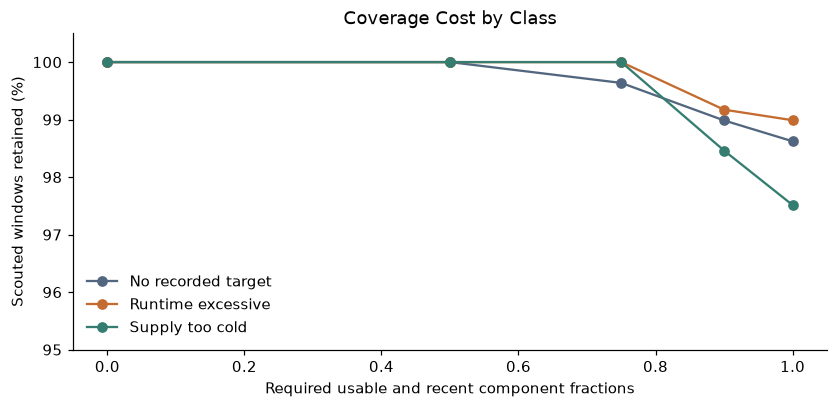

In [5]:
features, provenance = design.aggregate_scout_points(db, points)
scouted = points.merge(features, on="case_id", validate="one_to_one").merge(
    provenance, on="case_id", validate="one_to_one")
design.save_frame(db, "scout_features", features)
design.save_frame(db, "window_provenance", provenance)
sensitivity = design.coverage_sensitivity(scouted)
design.save_frame(db, "coverage_sensitivity", sensitivity)
display(sensitivity)

fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
for label, colour, name in zip(labels, colours, short_labels):
    part = sensitivity[sensitivity.reference_label == label]
    ax.plot(part.fraction_required, part.retained / part.scouted * 100, marker="o", color=colour, label=name)
ax.set(xlabel="Required usable and recent component fractions", ylabel="Scouted windows retained (%)",
       title="Coverage Cost by Class", ylim=(95, 100.5))
ax.legend(frameon=False)
show_figure(fig, "01_coverage_sensitivity.png")

## 6. Form the Training Pilot

Use 0.75 for both component fractions while retaining the original eight-of-twelve channel rule. This requires most observed components to contribute and limits complete disappearance relative to the recent roster. Compare its class and site retention with 0.50, 0.90, and full coverage in the table above. Sampling is capped before this filter, so rejected cases reduce the final class counts.

,cases,sites
reference_label,,
NoRecordedTarget,1375,46
RuntimeExcessive,1088,45
SupplyTempTooCold,845,36


,usable_component_fraction,recent_component_fraction,bin_coverage
reference_label,,,
NoRecordedTarget,1.0,1.0,0.969
RuntimeExcessive,1.0,1.0,0.969
SupplyTempTooCold,1.0,1.0,0.972


The 0.75 rule retains **3,308 of 3,313** scouted windows (**99.8%**) across **46** training sites. These windows supply the exploratory feature and logistic diagnostics below.

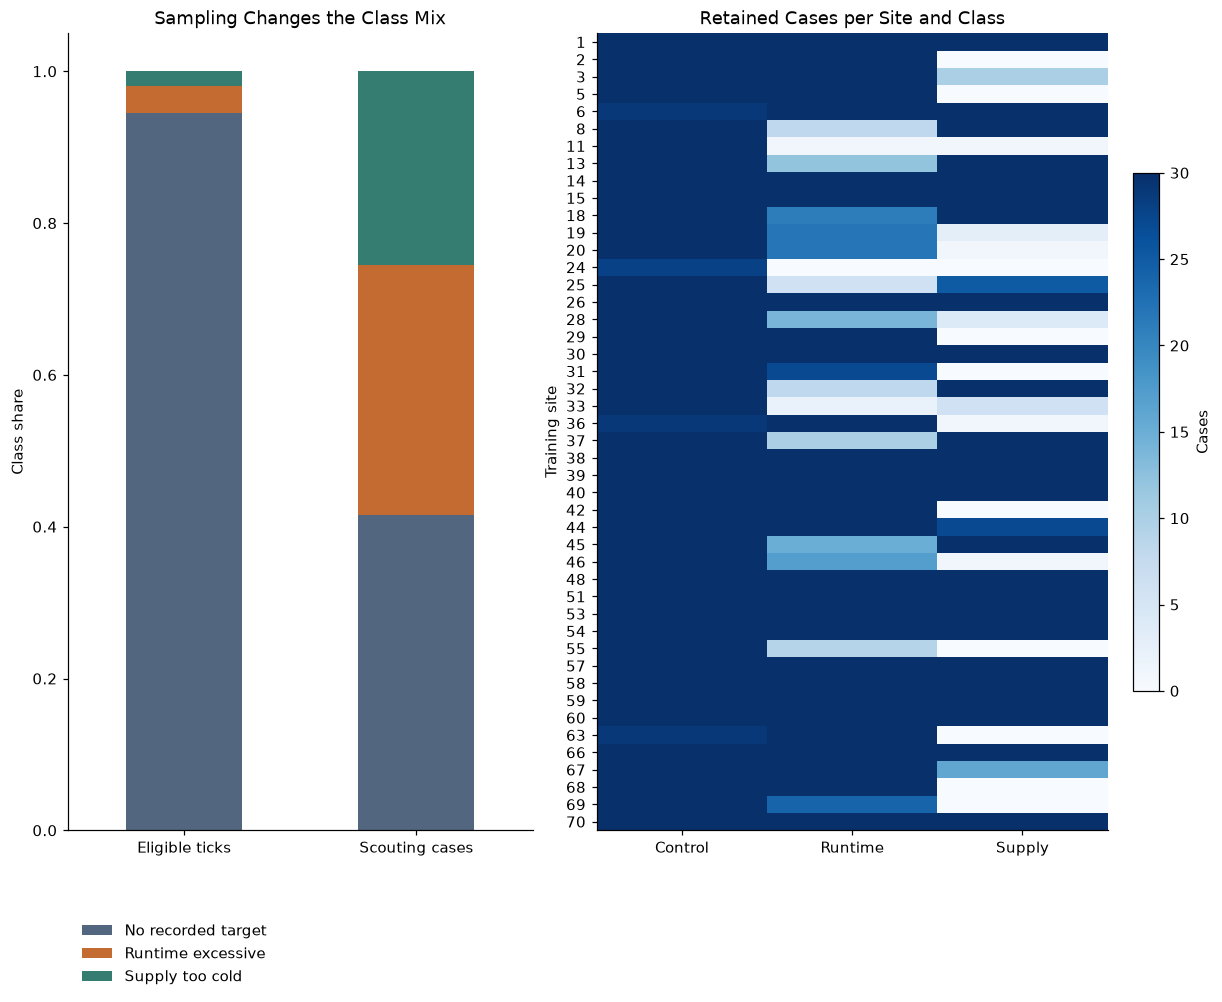

In [6]:
coverage_threshold = 0.75
keep = (scouted.usable_component_fraction >= coverage_threshold) & (
    scouted.recent_component_fraction >= coverage_threshold)
cases = scouted.loc[keep].sort_values(["site_id", "decision_time"]).reset_index(drop=True)
feature_columns = list(features.columns)
private_columns = list(points.columns) + [c for c in provenance.columns if c != "case_id"]
design.save_frame(db, "case_features", cases[feature_columns])
design.save_frame(db, "private_case_scores", cases[private_columns])
display(cases.groupby("reference_label").agg(cases=("case_id", "size"), sites=("site_id", "nunique")).reindex(labels))
display(cases.groupby("reference_label")[list(design.QUALITY_COLUMNS)].median().reindex(labels).round(3))
display(Markdown(f"The 0.75 rule retains **{len(cases):,} of {len(scouted):,}** scouted windows "
    f"(**{len(cases)/len(scouted):.1%}**) across **{cases.site_id.nunique()}** training sites. "
    "These windows supply the exploratory feature and logistic diagnostics below."))

counts = pd.crosstab(cases.site_id, cases.reference_label).reindex(columns=labels, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 9), gridspec_kw={"width_ratios": [1, 1.1]}, layout="constrained")
shares = pd.DataFrame({"Eligible ticks": support.tick_share,
    "Scouting cases": cases.reference_label.value_counts(normalize=True).reindex(labels)})
shares.index = short_labels
shares.T.plot.bar(stacked=True, color=colours, ax=axes[0], rot=0)
axes[0].set(ylabel="Class share", title="Sampling Changes the Class Mix")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.10))
im = axes[1].imshow(counts, aspect="auto", cmap="Blues", vmin=0, vmax=design.CASE_CAP)
axes[1].set(xticks=range(3), xticklabels=["Control", "Runtime", "Supply"],
            yticks=range(len(counts)), yticklabels=counts.index, ylabel="Training site",
            title="Retained Cases per Site and Class")
fig.colorbar(im, ax=axes[1], label="Cases", shrink=0.65)
show_figure(fig, "02_sampling_and_site_support.png")

## 7. Examine Class Overlap and Feature Redundancy

The plots compare case-level medians on native scales. Overlap between the classes limits what a single channel can distinguish. Linear axes retain the native values, and the table records the interquartile spread within each class.

The main candidate feature set uses typical component median, IQR, change, and the lowest and highest component median for channels 1, 2, 4, and 5. Three coverage measures and two state proportions add context. Mean, standard deviation, minimum, maximum, and range remain inspectable supplementary metrics. Check their redundancy before expanding the model.

ch1_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                            715.0   
                  0.50                            728.0   
                  0.75                            738.0   
RuntimeExcessive  0.25                            723.0   
                  0.50                            728.5   
                  0.75                            736.0   
SupplyTempTooCold 0.25                            729.0   
                  0.50                            735.0   
                  0.75                            749.5   

                        ch2_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                           622.62   
                  0.50                           670.75   
                  0.75                           704.12   
RuntimeExcessive  0.25                           571.00   
                  0.50                           604.50   
                  0.75                           653.00   
SupplyTempTooCold 0.25                           596.50   
                  0.50                           651.00   
                  0.75                           707.00   

                        ch3_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                             1.00   
                  0.50                             3.00   
                  0.75                            37.00   
RuntimeExcessive  0.25                            37.00   
                  0.50                            69.00   
                  0.75                            69.00   
SupplyTempTooCold 0.25                             1.00   
                  0.50                            52.25   
                  0.75                            69.00   

                        ch4_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                           552.75   
                  0.50                           574.00   
                  0.75                           604.50   
RuntimeExcessive  0.25                           585.00   
                  0.50                           616.00   
                  0.75                           637.00   
SupplyTempTooCold 0.25                           551.00   
                  0.50                           586.50   
                  0.75                           621.25   

                        ch5_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                            700.0   
                  0.50                            700.0   
                  0.75                            704.5   
RuntimeExcessive  0.25                            689.0   
                  0.50                            700.0   
                  0.75                            709.0   
SupplyTempTooCold 0.25                            694.5   
                  0.50                            700.0   
                  0.75                            709.0   

                        ch6_median_of_component_medians  \
reference_label                                           
NoRecordedTarget  0.25                             29.0   
                  0.50                             40.0   
                  0.75                             99.0   
RuntimeExcessive  0.25                             29.0   
                  0.50                             29.0   
                  0.75                             40.0   
SupplyTempTooCold 0.25                             29.0   
                  0.50                             40.0   
                  0.75                             99.0   

                        ch7_median_of_component_medians  
reference_label                                          
NoRecord

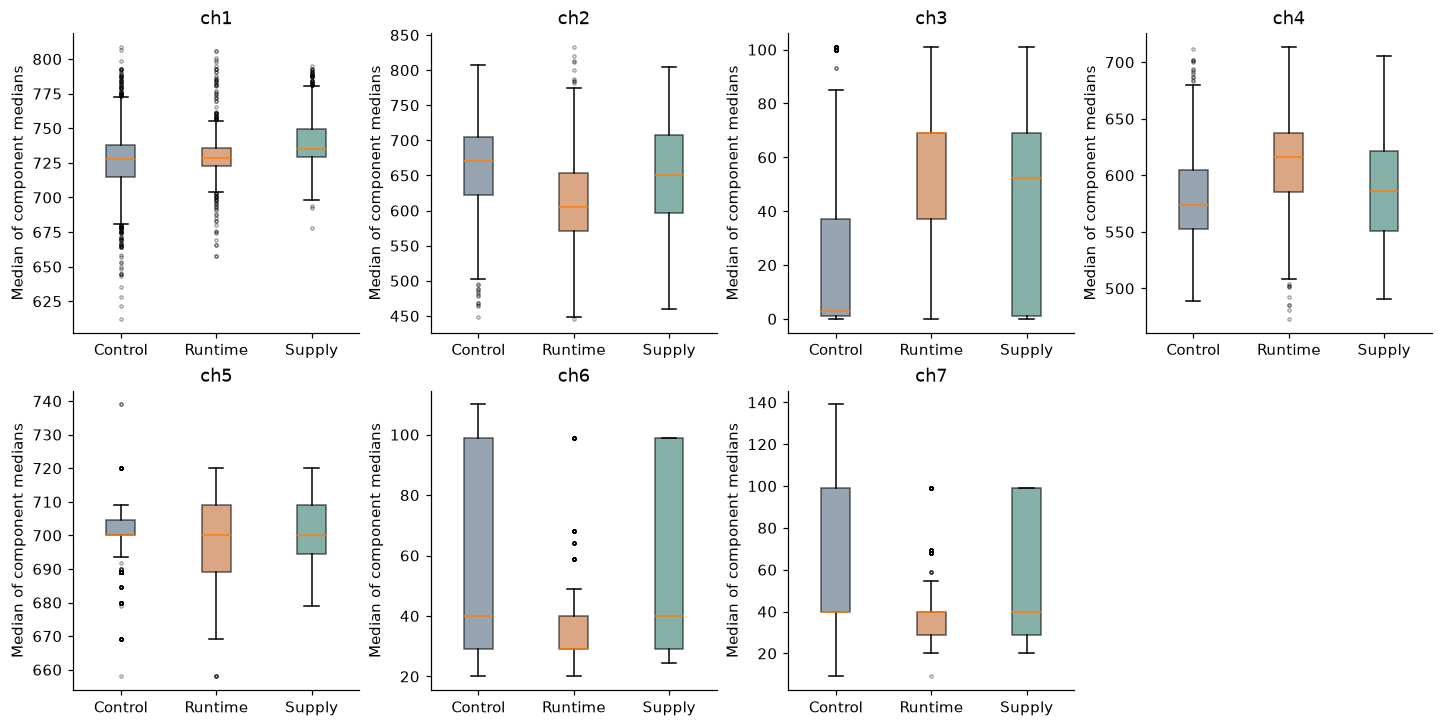

,feature_a,feature_b,spearman_r
3,ch2_lowest_component_median,ch4_highest_component_median,-1.000
0,ch2_median_of_component_medians,ch4_median_of_component_medians,-1.000
4,ch2_highest_component_median,ch4_lowest_component_median,-1.000
2,ch2_median_of_component_changes,ch4_median_of_component_changes,-0.999
1,ch2_median_of_component_iqrs,ch4_median_of_component_iqrs,0.998
5,ch6_median_of_component_iqrs,ch7_median_of_component_iqrs,0.995
6,ch6_median_of_component_changes,ch7_median_of_component_changes,0.995
7,occupied_fraction,setback_fraction,-0.984


,channel,mean_vs_median_r,std_vs_iqr_r
0,ch1,0.994,0.848
1,ch2,0.964,0.818
2,ch3,0.925,0.695
3,ch4,0.965,0.818
4,ch5,0.974,0.728
5,ch6,0.943,0.754
6,ch7,0.944,0.751


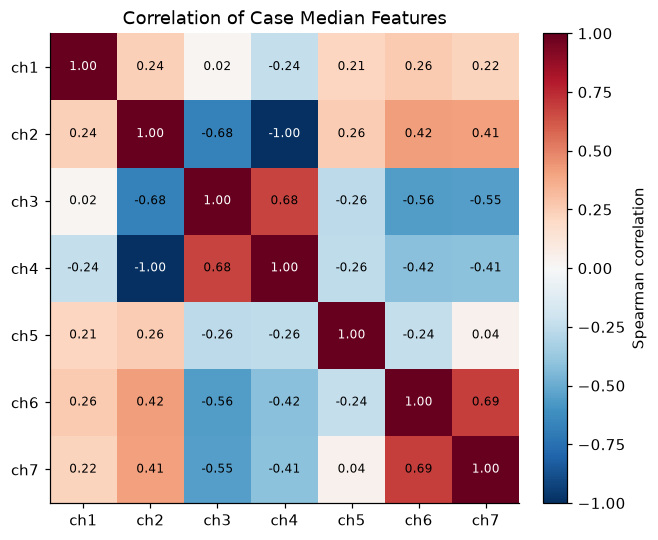

In [7]:
medians = [f"{ch}_median_of_component_medians" for ch in design.CHANNELS]
class_summary = cases.groupby("reference_label")[medians].quantile([0.25, 0.5, 0.75])
display(class_summary.round(2))
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), layout="constrained")
for ax, ch, column in zip(axes.flat, design.CHANNELS, medians):
    data = [cases.loc[cases.reference_label == label, column].dropna() for label in labels]
    box = ax.boxplot(data, tick_labels=["Control", "Runtime", "Supply"], patch_artist=True,
                     flierprops={"markersize": 2, "alpha": 0.35})
    for patch, colour in zip(box["boxes"], colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.6)
    ax.set(title=ch, ylabel="Median of component medians")
axes.flat[-1].axis("off")
show_figure(fig, "03_class_distributions.png")

pairs = design.correlated_pairs(cases[design.ALL_FEATURES])
design.save_frame(db, "correlated_features", pairs)
display(pairs.head(12).round(3))
supplementary = []
for ch in design.CHANNELS:
    median_col = f"{ch}_median_of_component_medians"
    mean_col = f"{ch}_median_of_component_means"
    std_col = f"{ch}_median_of_component_stds"
    iqr_col = f"{ch}_median_of_component_iqrs"
    supplementary.append((ch, cases[[median_col, mean_col]].corr(method="spearman").iloc[0, 1],
                          cases[[std_col, iqr_col]].corr(method="spearman").iloc[0, 1]))
display(pd.DataFrame(supplementary, columns=["channel", "mean_vs_median_r", "std_vs_iqr_r"]).round(3))

fig, ax = plt.subplots(figsize=(5.8, 4.8), layout="constrained")
matrix = cases[medians].corr(method="spearman").to_numpy()
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(7), xticklabels=design.CHANNELS, yticks=range(7), yticklabels=design.CHANNELS,
       title="Correlation of Case Median Features")
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{matrix[i,j]:.2f}", ha="center", va="center",
                color="white" if abs(matrix[i,j]) > 0.7 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="Spearman correlation")
show_figure(fig, "04_feature_redundancy.png")

## 8. Assess Dependence and the Design Matrix

Three-hour spacing removes direct sharing of measurement bins, while measurements from the same installation can remain related. The lag table measures Spearman correlation between consecutive selected cases within each site, using sites with at least ten retained cases. The gaps vary, so this is a dependence screen.

The matrix diagnostic checks constants, missingness, rank, and conditioning. Pairwise redundancy removal can reduce unstable coefficients. L2 regularisation constrains the remaining correlated directions. In the predictive checks, each fold learns its own imputation, clipping bounds, feature retention, and scaling from its fitting sites.

In [8]:
lag_records = []
for column in medians[:2]:
    for site, part in cases.groupby("site_id"):
        if len(part) >= 10:
            correlation = part[column].corr(part[column].shift(1), method="spearman")
            lag_records.append((column, site, correlation))
lag = pd.DataFrame(lag_records, columns=["feature", "site_id", "lag_spearman"])
design.save_frame(db, "within_site_dependence", lag)
display(lag.groupby("feature").lag_spearman.agg(["count", "median", "min", "max"]).round(3))

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
X = cases[design.MODEL_FEATURES]
filled = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X)
scaled = StandardScaler().fit_transform(filled)
screen = design.FoldTransform().fit(X)
reduced = StandardScaler().fit_transform(screen.transform(X))
matrix_audit = pd.DataFrame([
    ["candidate", scaled.shape[1], np.linalg.matrix_rank(scaled), np.linalg.cond(scaled)],
    ["screened", reduced.shape[1], np.linalg.matrix_rank(reduced), np.linalg.cond(reduced)]
], columns=["matrix", "columns", "rank", "condition_number"])
design.save_frame(db, "matrix_audit", matrix_audit)
display(matrix_audit)
display(pd.DataFrame({"missing_fraction": X.isna().mean(), "distinct": X.nunique()}).sort_values("distinct").head(10))
display(Markdown("Within-site clustering remains a study-design limitation. Grouping cross-validation by "
    "site estimates transfer to other training sites. Ordinary independent-case coefficient p-values "
    "would not account for this clustering."))

,count,median,min,max
feature,,,,
ch1_median_of_component_medians,46,0.491,0.114,0.798
ch2_median_of_component_medians,46,0.225,-0.194,0.607


,matrix,columns,rank,condition_number
0,candidate,25,25,319.394521
1,screened,19,19,4.678925


,missing_fraction,distinct
usable_component_fraction,0.0,7
recent_component_fraction,0.0,11
ch5_highest_component_median,0.0,16
ch5_lowest_component_median,0.0,20
ch5_median_of_component_medians,0.0,23
ch5_median_of_component_changes,0.0,23
ch5_median_of_component_iqrs,0.0,24
bin_coverage,0.0,105
ch1_median_of_component_changes,0.0,176
ch1_median_of_component_iqrs,0.0,216


Within-site clustering remains a study-design limitation. Grouping cross-validation by site estimates transfer to other training sites. Ordinary independent-case coefficient p-values would not account for this clustering.

**Interpretation of the dependence and redundancy checks.** The channel 2 and channel 4 case medians have rank correlation about -0.99997. The declared feature order retains channel 2 when the fold screen removes its counterpart. Across this scouting cohort, screening reduces the standardised design's condition number from about 319 to 4.68. These results support a compact representation and caution against assigning independent physical meaning to the two coefficients.

The median adjacent-case correlations within sites are about 0.491 for the channel 1 median and 0.225 for channel 2. Cases can therefore remain related after their windows cease to overlap. Whole-site folds are part of the evaluation design.

## 9. Inspect the Log-Odds Relationship

For a multinomial model, each pairwise log-odds is linear in the chosen predictor representation. The following binned curves compare each target with the control class on three example features. Each bin uses a 0.5 continuity correction in its class counts. Curvature suggests a possible functional-form issue.

These are marginal plots in a sampled cohort. Other channels, sites, and states can affect their shape. A grouped comparison with a small spline basis below checks whether allowing curved main effects improves transfer. Predictor normality and equal variances are not logistic-regression requirements. [Penn State GLM assumptions](https://online.stat.psu.edu/stat504/Lesson06)

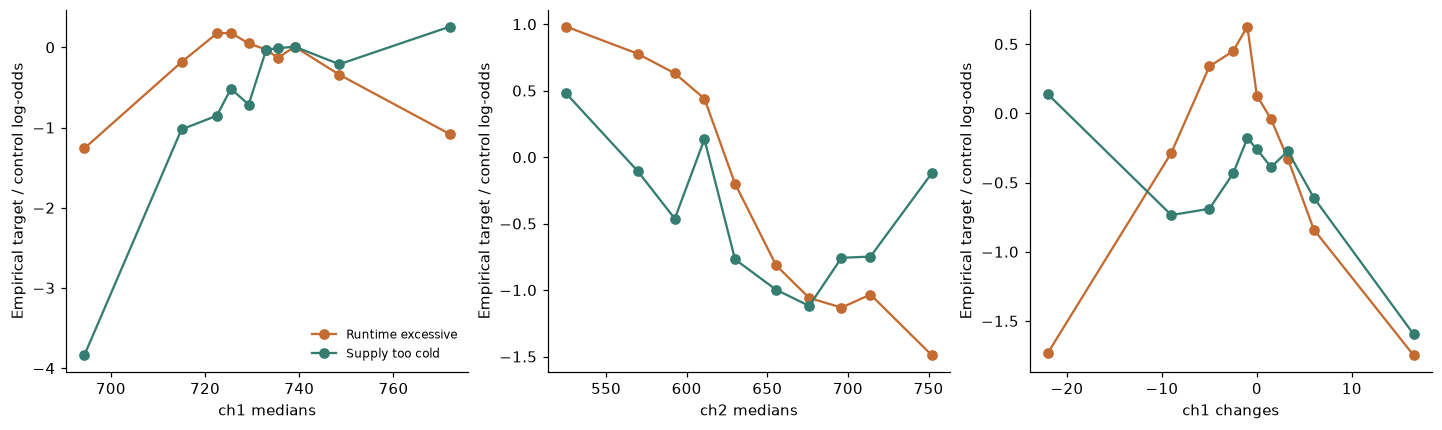

In [9]:
examples = ["ch1_median_of_component_medians", "ch2_median_of_component_medians",
            "ch1_median_of_component_changes"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, feature in zip(axes, examples):
    bins = pd.qcut(cases[feature], q=10, duplicates="drop")
    grouped = pd.crosstab(bins, cases.reference_label).reindex(columns=labels, fill_value=0)
    centres = cases.groupby(bins, observed=True)[feature].median().reindex(grouped.index)
    for label, colour, name in zip(labels[1:], colours[1:], short_labels[1:]):
        log_odds = np.log((grouped[label] + 0.5) / (grouped[design.CONTROL] + 0.5))
        ax.plot(centres, log_odds, marker="o", color=colour, label=name)
    ax.set(xlabel=feature.replace("_median_of_component_", " "),
           ylabel="Empirical target / control log-odds")
axes[0].legend(frameon=False, fontsize=8)
show_figure(fig, "05_empirical_log_odds.png")

## 10. Run a Grouped Logistic Diagnostic

All variants use the same five whole-site folds, L2 regularisation with C = 1, and fitting-fold class balancing. The first variant uses coverage alone to check whether data availability carries class information. The main linear pilot uses 25 candidate features. An expanded pilot adds the low-cardinality channels. Two sensitivity variants clip fitting-fold feature tails at the 0.5th and 99.5th percentiles, then either retain linear terms or add a cubic spline basis with four quantile knots.

Each fitting fold removes constant features and greedily removes pairs with absolute Spearman correlation at least 0.95, preserving the declared feature order. Fit and check sites remain disjoint. The case-wise scores are out of fold. Report fold variability and the gap between fit and check performance when assessing overfitting. These comparisons support design choices within training. [Grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#group-k-fold)

The spline comparison screens functional form using a modest additive extension. C is fixed across representations, so representation size and regularisation also affect the comparison. [SplineTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html)

Completed five grouped folds for coverage_only


Completed five grouped folds for linear


Completed five grouped folds for all_numeric


Completed five grouped folds for clipped_linear


Completed five grouped folds for clipped_spline


,macro_f1,fold_sd,log_loss,fit_macro_f1,predictors,converged
variant,,,,,,
coverage_only,0.287,0.053,1.098,0.289,3.0,True
linear,0.536,0.025,1.038,0.589,19.0,True
all_numeric,0.566,0.045,0.996,0.632,32.0,True
clipped_linear,0.540,0.028,0.933,0.593,18.8,True
clipped_spline,0.612,0.036,0.870,0.702,94.0,True


,clipping_minus_linear,spline_minus_clipped,all_numeric_minus_main
fold,,,
0,0.003,0.082,0.006
1,0.007,0.047,0.031
2,0.019,0.066,0.068
3,-0.012,0.109,0.030
4,0.006,0.056,0.014


,variant,fold,fit_cases,check_cases,check_sites,iterations,converged
0,coverage_only,0,2632,676,10,7,True
1,coverage_only,1,2645,663,9,5,True
2,coverage_only,2,2646,662,9,6,True
3,coverage_only,3,2654,654,9,7,True
4,coverage_only,4,2655,653,9,8,True
5,linear,0,2632,676,10,16,True
6,linear,1,2645,663,9,16,True
7,linear,2,2646,662,9,16,True
8,linear,3,2654,654,9,16,True
9,linear,4,2655,653,9,21,True


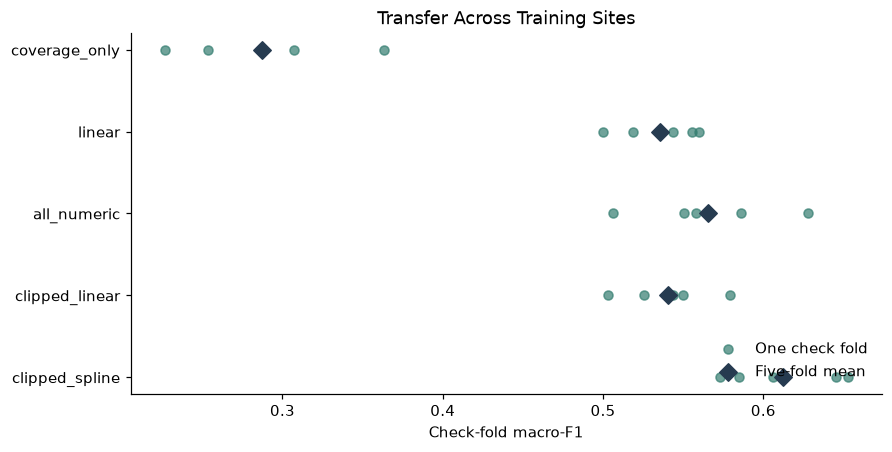

In [10]:
diagnostics = design.run_diagnostics(cases)
for name, frame in diagnostics.items():
    design.save_frame(db, name, frame)
metrics = diagnostics["fold_metrics"]
scores = diagnostics["oof_scores"]
summary = metrics.groupby("variant", sort=False).agg(
    macro_f1=("macro_f1", "mean"), fold_sd=("macro_f1", "std"),
    log_loss=("log_loss", "mean"), fit_macro_f1=("fit_macro_f1", "mean"),
    predictors=("predictors", "mean"), converged=("converged", "all"))
display(summary.round(3))
paired_folds = metrics.pivot(index="fold", columns="variant", values="macro_f1")
paired_effects = pd.DataFrame({
    "clipping_minus_linear": paired_folds.clipped_linear - paired_folds.linear,
    "spline_minus_clipped": paired_folds.clipped_spline - paired_folds.clipped_linear,
    "all_numeric_minus_main": paired_folds.all_numeric - paired_folds.linear})
design.save_frame(db, "paired_fold_effects", paired_effects.reset_index())
display(paired_effects.round(3))
display(metrics[["variant", "fold", "fit_cases", "check_cases", "check_sites", "iterations", "converged"]])
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, variant in enumerate(summary.index):
    part = metrics[metrics.variant == variant]
    ax.scatter(part.macro_f1, np.full(len(part), i), s=35, alpha=0.7, color="#347d70")
    ax.scatter(part.macro_f1.mean(), i, marker="D", s=65, color="#263b50")
ax.set(yticks=range(len(summary)), yticklabels=summary.index, xlabel="Check-fold macro-F1",
       title="Transfer Across Training Sites")
ax.scatter([], [], s=35, alpha=0.7, color="#347d70", label="One check fold")
ax.scatter([], [], marker="D", s=65, color="#263b50", label="Five-fold mean")
ax.legend(frameon=False, loc="lower right")
ax.invert_yaxis()
show_figure(fig, "06_grouped_logistic_diagnostics.png")

## 11. Examine Classification Errors and Shared Parameters

The confusion counts and per-class recall identify which case distinctions remain difficult. A reliability curve checks how scores correspond to observed class frequencies within this sampled cohort. Class balancing and case sampling change the fitting distribution, so these scores require further calibration evidence before operational probability interpretation. [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

For case i and class k, a fitted model computes z(i,k) = intercept(k) + sum of coefficient(k,j) × standardised feature(i,j). Softmax converts the three z values into class scores summing to one. The saved coefficient table is keyed by fold and class. The preprocessing table records its imputation medians, selected feature positions, and scaling values. The case score references the matching model ID. [Multinomial logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

,precision,recall,f1-score,support
NoRecordedTarget,0.743,0.576,0.649,1375.000
RuntimeExcessive,0.493,0.681,0.572,1088.000
SupplyTempTooCold,0.430,0.375,0.401,845.000
accuracy,0.559,0.559,0.559,0.559
macro avg,0.555,0.544,0.540,3308.000
weighted avg,0.581,0.559,0.560,3308.000


Recorded-target recall is **68.1%** for RuntimeExcessive and **37.5%** for SupplyTempTooCold. Inspect the off-diagonal counts to identify which comparison needs stronger features or contextual evidence.

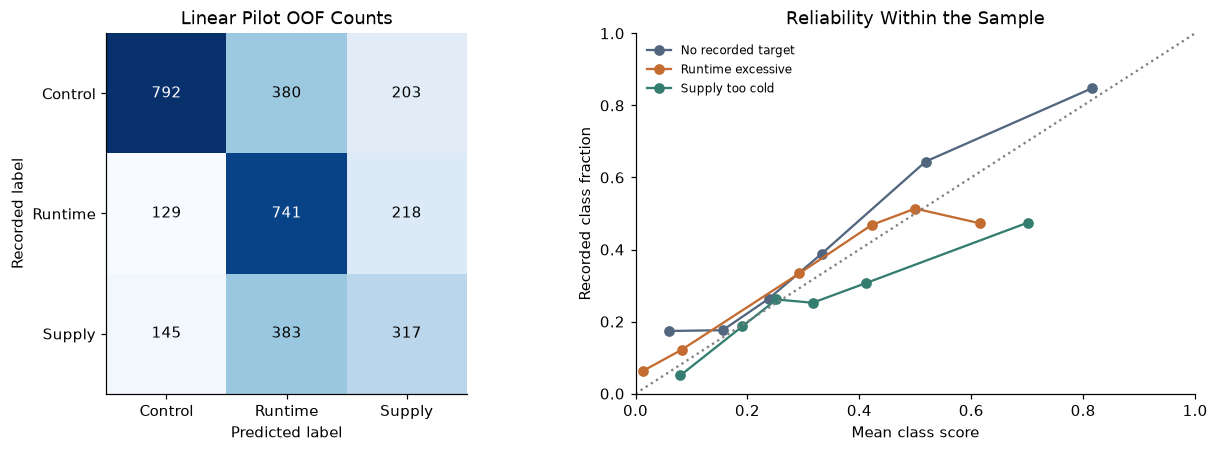

,fold,class,term,standardised_coefficient,magnitude
99,1,RuntimeExcessive,occupied_fraction,0.981361,0.981361
219,3,RuntimeExcessive,occupied_fraction,0.977958,0.977958
279,4,RuntimeExcessive,occupied_fraction,0.922965,0.922965
39,0,RuntimeExcessive,occupied_fraction,0.790835,0.790835
159,2,RuntimeExcessive,occupied_fraction,0.789824,0.789824
199,3,NoRecordedTarget,occupied_fraction,-0.660955,0.660955
259,4,NoRecordedTarget,occupied_fraction,-0.646727,0.646727
109,1,SupplyTempTooCold,ch2_lowest_component_median,-0.644895,0.644895
139,2,NoRecordedTarget,occupied_fraction,-0.614642,0.614642
19,0,NoRecordedTarget,occupied_fraction,-0.576015,0.576015


,linear_predictor,reconstructed_score
class,,
NoRecordedTarget,0.00832,0.31013
RuntimeExcessive,0.49308,0.50359
SupplyTempTooCold,-0.50140,0.18628


,case_id,fold,class,term,standardised_value,coefficient,contribution
39,df8166468d995271aa94446684034494,0,RuntimeExcessive,occupied_fraction,0.658030,0.790835,0.520393
19,df8166468d995271aa94446684034494,0,NoRecordedTarget,occupied_fraction,0.658030,-0.576015,-0.379035
5,df8166468d995271aa94446684034494,0,NoRecordedTarget,ch1_highest_component_median,-1.019557,-0.360538,0.367589
45,df8166468d995271aa94446684034494,0,SupplyTempTooCold,ch1_highest_component_median,-1.019557,0.301695,-0.307596
51,df8166468d995271aa94446684034494,0,SupplyTempTooCold,ch5_median_of_component_medians,-1.012371,0.271245,-0.274601
11,df8166468d995271aa94446684034494,0,NoRecordedTarget,ch5_median_of_component_medians,-1.012371,-0.262901,0.266154
1,df8166468d995271aa94446684034494,0,NoRecordedTarget,ch1_median_of_component_medians,-1.238222,-0.214758,0.265918
15,df8166468d995271aa94446684034494,0,NoRecordedTarget,ch5_highest_component_median,-1.146766,0.198984,-0.228188


The contribution calculation reproduces all three saved scores for case **df8166468d995271aa94446684034494**. Coefficient signs describe the fitted joint model and scaling. Correlated predictors and site differences limit causal or physical interpretations.

In [11]:
linear_scores = scores[scores.variant == "linear"].merge(
    cases[["case_id", "reference_label", "site_id"]], on="case_id", validate="one_to_one")
report = pd.DataFrame(classification_report(linear_scores.reference_label, linear_scores.predicted_label,
    labels=labels, output_dict=True, zero_division=0)).T
display(report.round(3))
display(Markdown(f"Recorded-target recall is **{report.loc[design.TARGETS[0], 'recall']:.1%}** for RuntimeExcessive "
    f"and **{report.loc[design.TARGETS[1], 'recall']:.1%}** for SupplyTempTooCold. Inspect the off-diagonal "
    "counts to identify which comparison needs stronger features or contextual evidence."))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
confusion = confusion_matrix(linear_scores.reference_label, linear_scores.predicted_label, labels=labels)
axes[0].imshow(confusion, cmap="Blues")
axes[0].set(xticks=range(3), xticklabels=["Control", "Runtime", "Supply"],
            yticks=range(3), yticklabels=["Control", "Runtime", "Supply"],
            xlabel="Predicted label", ylabel="Recorded label", title="Linear Pilot OOF Counts")
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, str(confusion[i,j]), ha="center", va="center",
                     color="white" if confusion[i,j] > confusion.max()/2 else "black")
from sklearn.calibration import calibration_curve
for label, colour, name in zip(labels, colours, short_labels):
    actual, predicted = calibration_curve(linear_scores.reference_label.eq(label),
        linear_scores[f"score_{label}"], n_bins=6, strategy="quantile")
    axes[1].plot(predicted, actual, marker="o", color=colour, label=name)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":")
axes[1].set(xlabel="Mean class score", ylabel="Recorded class fraction",
            title="Reliability Within the Sample", xlim=(0, 1), ylim=(0, 1))
axes[1].legend(frameon=False, fontsize=8)
show_figure(fig, "07_errors_and_reliability.png")

parameters = diagnostics["linear_parameters"]
display(parameters.assign(magnitude=parameters.standardised_coefficient.abs())
        .sort_values("magnitude", ascending=False).head(10))
contributions = diagnostics["example_contributions"]
logits = contributions.groupby("class").contribution.sum().reindex(sorted(labels))
reconstructed = pd.Series(softmax(logits.to_numpy()), index=logits.index, name="reconstructed_score")
case_id = contributions.case_id.iloc[0]
stored = linear_scores.set_index("case_id").loc[case_id, [f"score_{c}" for c in sorted(labels)]].astype(float)
assert np.allclose(reconstructed, stored.to_numpy())
display(pd.concat([logits.rename("linear_predictor"), reconstructed], axis=1).round(5))
display(contributions.assign(magnitude=contributions.contribution.abs())
        .sort_values("magnitude", ascending=False).head(8).drop(columns="magnitude"))
display(Markdown(f"The contribution calculation reproduces all three saved scores for case **{case_id}**. "
    "Coefficient signs describe the fitted joint model and scaling. Correlated predictors and site differences "
    "limit causal or physical interpretations."))

## 12. Record the Case Contract and Remaining Assumptions

The case contract preserves the three-hour trailing window, quarter-hour decisions, one point per positive episode, and non-overlapping windows within a site. The scouting sample motivates a 0.75 component-fraction threshold. The final validation/test sample size and episode timing policy can be frozen using this contract and the existing site manifest.

The results below distinguish directly checked conditions from modelling assumptions that remain approximate. A successful penalised fit establishes computational feasibility. It does not establish independent observations, a correct physical channel interpretation, or an adequate linear log-odds relationship.

In [12]:
checks = design.validate_scout(db, cases, scores)
for item in checks:
    print(item)

linear = summary.loc["linear"]
clip_gain = summary.loc["clipped_linear", "macro_f1"] - linear.macro_f1
curve_gain = summary.loc["clipped_spline", "macro_f1"] - summary.loc["clipped_linear", "macro_f1"]
assumptions = pd.DataFrame([
    ["Categorical outcome", "Checked", "Three mutually exclusive recorded classes at eligible decisions."],
    ["Time availability", "Checked", "Every contributing observation falls inside the trailing window."],
    ["Case independence", "Partial", "Windows are disjoint, while cases remain clustered by site."],
    ["Feature rank and redundancy", "Screened", "Fold-specific constants and highly correlated pairs are removed; L2 remains necessary."],
    ["Linear pairwise log-odds", "Unconfirmed", f"Spline minus clipped-linear mean macro-F1 is {curve_gain:+.3f}; inspect fold variability."],
    ["Outlier influence", "Screened", f"Clipped minus original linear mean macro-F1 is {clip_gain:+.3f}."],
    ["Separation and optimisation", "Screened", f"All diagnostic fits converged: {bool(metrics.converged.all())}; regularisation constrains extreme estimates."],
    ["Predictor normality", "No requirement", "Distribution plots guide feature interpretation and robust treatment."],
    ["Operational calibration", "Unconfirmed", "Scouting and class balancing alter class frequencies."],
    ["Label completeness", "Unconfirmed", "Log bracketing supports recorded controls but cannot certify absent faults."]
], columns=["condition", "assessment", "evidence_or_limit"])
design.save_frame(db, "assumption_audit", assumptions)
display(assumptions)

contract = {
    "version": "0.2.0", "scope": "training-site scouting and logistic diagnostics",
    "seed": design.SEED, "case_cap_per_site_class": design.CASE_CAP,
    "lookback_minutes": 180, "decision_step_minutes": 15, "minimum_bins_per_component_channel": 8,
    "usable_component_fraction": coverage_threshold, "recent_component_fraction": coverage_threshold,
    "recent_component_lookback_hours": 24, "minimum_within_site_spacing_minutes": 180,
    "positive_sampling": "one seeded random eligible tick per merged episode before overlap rejection",
    "control_sampling": "seeded eligible control ticks, round-robin class selection and site cap",
    "quality_filter_order": "after spacing and caps; rejected cases are not refilled in this pilot",
    "model_input_features": design.MODEL_FEATURES, "supplementary_features": [c for c in feature_columns if c not in design.MODEL_FEATURES],
    "fold_count": 5, "fold_group": "site_id", "regularisation_C": 1.0, "class_weight": "balanced",
    "source_bytes": source.stat().st_size,
    "python": platform.python_version(), "duckdb": duckdb.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__
}
with source.open("rb") as handle:
    contract["source_sha256"] = hashlib.file_digest(handle, "sha256").hexdigest()
contract["code_sha256"] = {}
for name in ("phm_case_design.py", "phm_case_samples.py", "phm_preprocessing.py"):
    contract["code_sha256"][name] = hashlib.sha256((project / name).read_bytes()).hexdigest()
design.save_frame(db, "case_contract", pd.DataFrame([{"contract_json": json.dumps(contract)}]))
db.close()
staged.replace(destination)
scratch.cleanup()
print(f"Saved {destination}")
print(f"{len(cases):,} training scouting cases | {(perf_counter()-started)/60:.1f} minutes")
display(Markdown(f"**Design conclusion.** The retained cases support a reproducible diagnostic pilot with "
    f"mean grouped macro-F1 **{linear.macro_f1:.3f}** and fold SD **{linear.fold_sd:.3f}** for the main linear model. "
    f"Clipping changes mean macro-F1 by **{clip_gain:+.3f}**, and adding curved terms changes it by "
    f"**{curve_gain:+.3f}** relative to the clipped model. Use these differences alongside class recall, site support, "
    "and fold variation when choosing the final representation. The saved case table supplies the basic "
    "summary statistics, and the out-of-fold score table links each case to its logistic model."))
display(Markdown("**Preparation decision.** Preserve robust component summaries and coverage, use one seeded "
    "time per positive episode, and maintain three-hour separation. Retain the 0.75 coverage threshold for this "
    "pilot. Start final baseline development with the transparent linear model, then assess the curved "
    "representation using the reserved validation sites before freezing it. The better spline diagnostic "
    "means linear log-odds remain an unresolved modelling assumption. Verify channel encodings before "
    "promoting the all-numeric sensitivity to the main model. The current cross-validation comparisons are "
    "exploratory design evidence and require a later frozen evaluation."))

Training Sites Only
Unique Cases and Positive Episodes
Strict Trailing Windows
Three-Hour Separation Within Sites
Valid Coverage Fractions
One Out-of-Fold Score Per Case and Variant
Whole-Site Fold Assignment
Three Scores Sum to One


,condition,assessment,evidence_or_limit
0,Categorical outcome,Checked,Three mutually exclusive recorded classes at eligible decisions.
1,Time availability,Checked,Every contributing observation falls inside the trailing window.
2,Case independence,Partial,"Windows are disjoint, while cases remain clustered by site."
3,Feature rank and redundancy,Screened,Fold-specific constants and highly correlated pairs are removed; L2 remains necessary.
4,Linear pairwise log-odds,Unconfirmed,Spline minus clipped-linear mean macro-F1 is +0.072; inspect fold variability.
5,Outlier influence,Screened,Clipped minus original linear mean macro-F1 is +0.005.
6,Separation and optimisation,Screened,All diagnostic fits converged: True; regularisation constrains extreme estimates.
7,Predictor normality,No requirement,Distribution plots guide feature interpretation and robust treatment.
8,Operational calibration,Unconfirmed,Scouting and class balancing alter class frequencies.
9,Label completeness,Unconfirmed,Log bracketing supports recorded controls but cannot certify absent faults.


Saved C:\Users\ges2j\OneDrive\Desktop\Assessments\CP5403\Datasets\PHM15-prepared\case_design.duckdb
3,308 training scouting cases | 2.9 minutes


**Design conclusion.** The retained cases support a reproducible diagnostic pilot with mean grouped macro-F1 **0.536** and fold SD **0.025** for the main linear model. Clipping changes mean macro-F1 by **+0.005**, and adding curved terms changes it by **+0.072** relative to the clipped model. Use these differences alongside class recall, site support, and fold variation when choosing the final representation. The saved case table supplies the basic summary statistics, and the out-of-fold score table links each case to its logistic model.

**Preparation decision.** Preserve robust component summaries and coverage, use one seeded time per positive episode, and maintain three-hour separation. Retain the 0.75 coverage threshold for this pilot. Start final baseline development with the transparent linear model, then assess the curved representation using the reserved validation sites before freezing it. The better spline diagnostic means linear log-odds remain an unresolved modelling assumption. Verify channel encodings before promoting the all-numeric sensitivity to the main model. The current cross-validation comparisons are exploratory design evidence and require a later frozen evaluation.